In [1]:
# ===== Install Libraries =====
!pip install pyspark scikit-learn lightgbm xgboost matplotlib seaborn joblib

# ===== Import All Required Libraries =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pickle
from datetime import datetime, timedelta

# PySpark libraries
from pyspark.sql import SparkSession
from pyspark.sql.window import Window
from pyspark.sql.functions import col, lag, avg, stddev, max, min, date_format, row_number
from pyspark.ml.feature import VectorAssembler, MinMaxScaler, StandardScaler

# Machine Learning libraries
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
import lightgbm as lgb
import xgboost as xgb

# Set random seeds for reproducibility
np.random.seed(42)

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, to_timestamp
import gdown
import os

# Khởi tạo Spark Session
spark = SparkSession.builder \
    .appName("Vietnam_IoT_TimeSeries") \
    .getOrCreate()

# ==========================================
# 1. Tải file từ Google Drive
# ==========================================
file_id = '1FUVHpnYihgggiRHW2l7gwZC1C1sNYlhe'
url = f'https://drive.google.com/uc?id={file_id}'
output_file = 'Vietnam_IoT_Final_Dataset.csv'

if not os.path.exists(output_file):
    print(f"Đang tải file {output_file} về máy...")
    gdown.download(url, output_file, quiet=False)
    print("\nTải xong!")
else:
    print(f"File {output_file} đã tồn tại. Bỏ qua bước tải.")

# ==========================================
# 2. Đọc CSV vào Spark DataFrame
# ==========================================
df_spark = spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv(output_file)

print(f"Tổng số dòng: {df_spark.count()}")
print(f"Số cột: {len(df_spark.columns)}")
df_spark.printSchema()


Đang tải file Vietnam_IoT_Final_Dataset.csv về máy...


Downloading...
From (original): https://drive.google.com/uc?id=1FUVHpnYihgggiRHW2l7gwZC1C1sNYlhe
From (redirected): https://drive.google.com/uc?id=1FUVHpnYihgggiRHW2l7gwZC1C1sNYlhe&confirm=t&uuid=49cf89bd-48ad-4321-847f-a21d51d875e9
To: /content/Vietnam_IoT_Final_Dataset.csv
100%|██████████| 191M/191M [00:03<00:00, 56.4MB/s]



Tải xong!
Tổng số dòng: 1143360
Số cột: 17
root
 |-- timestamp: timestamp (nullable = true)
 |-- temperature: double (nullable = true)
 |-- humidity: double (nullable = true)
 |-- apparent_temp: double (nullable = true)
 |-- weather_code: double (nullable = true)
 |-- pressure: double (nullable = true)
 |-- rain: double (nullable = true)
 |-- wind_speed: double (nullable = true)
 |-- wind_direction: double (nullable = true)
 |-- wind_gusts: double (nullable = true)
 |-- solar_radiation: double (nullable = true)
 |-- visibility: string (nullable = true)
 |-- cloud_cover: double (nullable = true)
 |-- is_day: double (nullable = true)
 |-- city: string (nullable = true)
 |-- region: string (nullable = true)
 |-- sensor_id: string (nullable = true)



In [3]:
# 1. Thông tin cơ bản về dataset
print("\n📊 1. TỔNG QUAN DỮ LIỆU")
print("-" * 50)
print(f"Tổng số quan sát: {df_spark.count():,}")
print(f"Tổng số cột: {len(df_spark.columns)}")
print(f"Thời gian dữ liệu: {df_spark.agg({'timestamp': 'min'}).collect()[0][0]} đến {df_spark.agg({'timestamp': 'max'}).collect()[0][0]}")


# 2. Thống kê mô tả các biến số học
print("\n📈 2. THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ HỌC")
print("-" * 50)

# Chọn các cột số học để phân tích
numeric_columns = ['temperature', 'humidity', 'apparent_temp', 'pressure',
                   'rain', 'wind_speed', 'wind_direction', 'wind_gusts',
                   'solar_radiation', 'cloud_cover']

# Lấy thống kê mô tả từ Spark
from pyspark.sql.functions import mean, stddev, min, max, count, col

# Tính tất cả các thống kê một lần cho tất cả các cột số học
stats_df_aggregated = df_spark.select(
    [mean(col(c)).alias(f'mean_{c}') for c in numeric_columns] +
    [stddev(col(c)).alias(f'std_{c}') for c in numeric_columns] +
    [min(col(c)).alias(f'min_{c}') for c in numeric_columns] +
    [max(col(c)).alias(f'max_{c}') for c in numeric_columns] +
    [count(col(c)).alias(f'count_{c}') for c in numeric_columns]
)

# Chuyển sang pandas để hiển thị đẹp hơn
stats_data = []
# Lấy hàng kết quả duy nhất từ DataFrame Spark
stats_row = stats_df_aggregated.collect()[0]

for col_name in numeric_columns:
    stats_data.append({
        'Biến': col_name,
        'Trung bình': round(stats_row[f'mean_{col_name}'], 2),
        'Độ lệch chuẩn': round(stats_row[f'std_{col_name}'], 2),
        'Giá trị nhỏ nhất': round(stats_row[f'min_{col_name}'], 2),
        'Giá trị lớn nhất': round(stats_row[f'max_{col_name}'], 2),
        'Số quan sát': stats_row[f'count_{col_name}']
    })

stats_pd = pd.DataFrame(stats_data)
print(stats_pd.to_string(index=False))

# 3. Phân tích biến phân loại
print("\n🏷️ 3. PHÂN TÍCH BIẾN PHÂN LOẠI")
print("-" * 50)

# Phân tích weather_code
weather_code_dist = df_spark.groupBy("weather_code").count().orderBy("count", ascending=False).limit(10)
print("Phân bố 10 mã thời tiết phổ biến nhất:")
print(weather_code_dist.toPandas().to_string(index=False))

# Phân tích region
region_dist = df_spark.groupBy("region").count().orderBy("count", ascending=False)
print("\nPhân bố theo vùng:")
print(region_dist.toPandas().to_string(index=False))

# Phân tích is_day
day_night_dist = df_spark.groupBy("is_day").count()
print("\nPhân bố ban ngày/ban đêm:")
day_night_pd = day_night_dist.toPandas()
day_night_pd['is_day'] = day_night_pd['is_day'].map({0: 'Ban đêm', 1: 'Ban ngày'})
print(day_night_pd.to_string(index=False))


📊 1. TỔNG QUAN DỮ LIỆU
--------------------------------------------------
Tổng số quan sát: 1,143,360
Tổng số cột: 17
Thời gian dữ liệu: 1999-12-31 17:00:00 đến 2026-01-31 16:00:00

📈 2. THỐNG KÊ MÔ TẢ CÁC BIẾN SỐ HỌC
--------------------------------------------------
           Biến  Trung bình  Độ lệch chuẩn  Giá trị nhỏ nhất  Giá trị lớn nhất  Số quan sát
    temperature       25.47           4.44              4.37             40.15      1143360
       humidity       80.90          13.36             20.00            100.00      1143360
  apparent_temp       29.35           6.30             -0.39             48.03      1143360
       pressure     1009.44           5.39            963.32           1038.88      1143360
           rain        0.23           0.86              0.00             56.90      1143360
     wind_speed        8.75           4.66              0.00             78.93      1143360
 wind_direction      159.38          95.07              0.43            360.00      11


DATA EXPLORATION

Missing values per column:
visibility: 1143360 missing values

Unique cities: 5
+-----------+
|       city|
+-----------+
|    Da Nang|
|    Can Tho|
|     Ha Noi|
|  Hai Phong|
|Ho Chi Minh|
+-----------+


Date range: 1999-12-31 17:00:00 to 2026-01-31 16:00:00


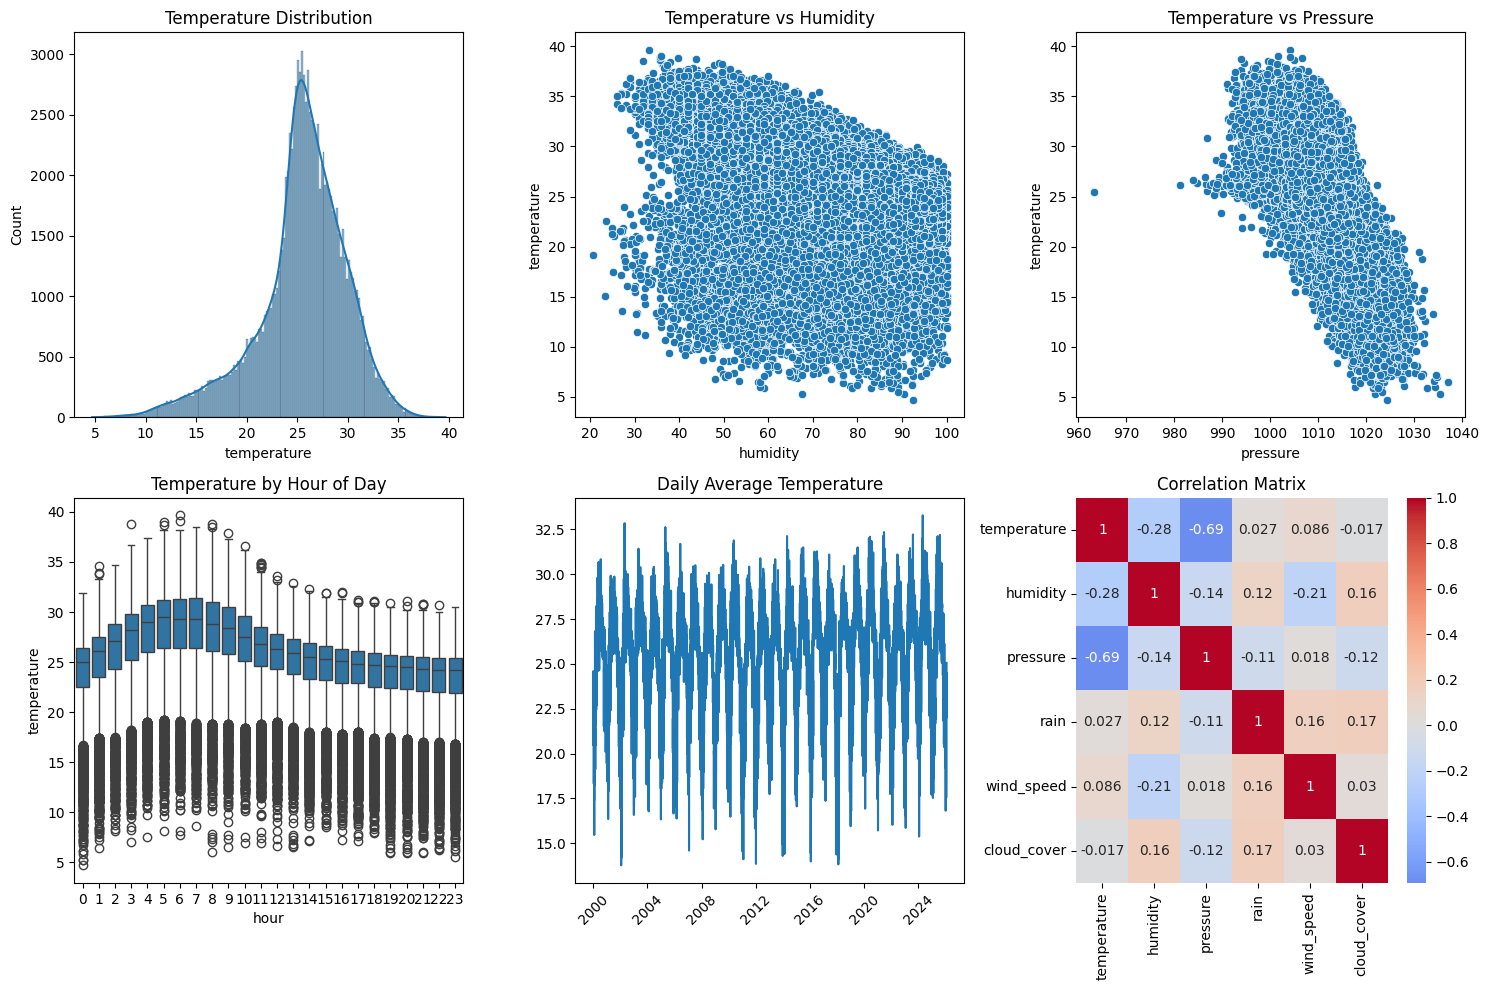

In [4]:
# ===== Data Exploration & Visualization =====
def explore_data(df):
    """Exploratory data analysis"""
    print("\n" + "="*50)
    print("DATA EXPLORATION")
    print("="*50)

    # Check for missing values
    print("\nMissing values per column:")
    for column in df.columns:
        missing_count = df.filter(col(column).isNull()).count()
        if missing_count > 0:
            print(f"{column}: {missing_count} missing values")

    # Check unique cities
    print(f"\nUnique cities: {df.select('city').distinct().count()}")
    df.select('city').distinct().show()

    # Check date range
    min_date = df.select(min("timestamp")).collect()[0][0]
    max_date = df.select(max("timestamp")).collect()[0][0]
    print(f"\nDate range: {min_date} to {max_date}")

    # Convert to pandas for visualization (if data is not too large)
    try:
        sample_df = df.sample(0.1).toPandas()  # Sample 10% for visualization

        # Plot temperature distribution
        plt.figure(figsize=(15, 10))

        plt.subplot(2, 3, 1)
        sns.histplot(sample_df['temperature'], kde=True)
        plt.title('Temperature Distribution')

        plt.subplot(2, 3, 2)
        sns.scatterplot(data=sample_df, x='humidity', y='temperature')
        plt.title('Temperature vs Humidity')

        plt.subplot(2, 3, 3)
        sns.scatterplot(data=sample_df, x='pressure', y='temperature')
        plt.title('Temperature vs Pressure')

        plt.subplot(2, 3, 4)
        sample_df['hour'] = pd.to_datetime(sample_df['timestamp']).dt.hour
        sns.boxplot(data=sample_df, x='hour', y='temperature')
        plt.title('Temperature by Hour of Day')

        plt.subplot(2, 3, 5)
        # Convert timestamp to date for time series plot
        sample_df['date'] = pd.to_datetime(sample_df['timestamp']).dt.date
        daily_avg = sample_df.groupby('date')['temperature'].mean().reset_index()
        plt.plot(daily_avg['date'], daily_avg['temperature'])
        plt.title('Daily Average Temperature')
        plt.xticks(rotation=45)

        plt.subplot(2, 3, 6)
        # Correlation heatmap
        numeric_cols = ['temperature', 'humidity', 'pressure', 'rain', 'wind_speed', 'cloud_cover']
        corr_matrix = sample_df[numeric_cols].corr()
        sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
        plt.title('Correlation Matrix')

        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Visualization skipped due to: {e}")

explore_data(df_spark)

In [5]:
# ========== PHẦN 3: TIỀN XỬ LÝ DỮ LIỆU ==========
from pyspark.sql.window import Window
from pyspark.sql.functions import lag, avg, hour, dayofweek, month, dayofyear, year, sin, cos, when
from pyspark.sql.types import DoubleType

def preprocess_data(df):
    """
    Tiền xử lý dữ liệu thời gian và tạo các đặc trưng
    """
    # Xóa cột visibility vì có giá trị NaN
    df = df.drop("visibility")

    # Tạo các đặc trưng thời gian
    df = df.withColumn("hour", hour(col("timestamp")))
    df = df.withColumn("day_of_week", dayofweek(col("timestamp")))
    df = df.withColumn("month", month(col("timestamp")))
    df = df.withColumn("day_of_year", dayofyear(col("timestamp")))
    df = df.withColumn("year", year(col("timestamp")))

    # Tạo đặc trưng cyclic cho giờ
    df = df.withColumn("hour_sin", sin(2 * np.pi * col("hour") / 24))
    df = df.withColumn("hour_cos", cos(2 * np.pi * col("hour") / 24))

    # Tạo đặc trưng cyclic cho ngày trong tuần
    df = df.withColumn("dow_sin", sin(2 * np.pi * col("day_of_week") / 7))
    df = df.withColumn("dow_cos", cos(2 * np.pi * col("day_of_week") / 7))

    # Tạo đặc trưng cyclic cho tháng
    df = df.withColumn("month_sin", sin(2 * np.pi * col("month") / 12))
    df = df.withColumn("month_cos", cos(2 * np.pi * col("month") / 12))

    # Chuyển đổi city thành mã số
    city_mapping = {"Da Nang": 0, "Hai Phong": 1, "Can Tho": 2, "Ha Noi": 3, "Ho Chi Minh": 4}
    mapping_expr = when(col("city") == "Da Nang", city_mapping["Da Nang"]) \
        .when(col("city") == "Hai Phong", city_mapping["Hai Phong"]) \
        .when(col("city") == "Can Tho", city_mapping["Can Tho"]) \
        .when(col("city") == "Ha Noi", city_mapping["Ha Noi"]) \
        .when(col("city") == "Ho Chi Minh", city_mapping["Ho Chi Minh"]) \
        .otherwise(-1)

    df = df.withColumn("city_code", mapping_expr.cast(DoubleType()))

    # Thêm lag features cho temperature
    window_spec = Window.partitionBy("city").orderBy("timestamp")

    for lag_hours in [1, 2, 3, 24, 48]:
        df = df.withColumn(f"temp_lag_{lag_hours}",
                          lag("temperature", lag_hours).over(window_spec))

    # Thêm moving averages
    df = df.withColumn("temp_ma_24h",
                      avg("temperature").over(window_spec.rowsBetween(-23, 0)))
    df = df.withColumn("temp_ma_168h",
                      avg("temperature").over(window_spec.rowsBetween(-167, 0)))

    # Xóa các dòng có giá trị null
    df = df.na.drop()

    return df

# Áp dụng tiền xử lý
df_processed = preprocess_data(df_spark)
print(f"Số dòng sau khi tiền xử lý: {df_processed.count()}")
print(f"Số cột: {len(df_processed.columns)}")
df_processed.select("timestamp", "city", "temperature", "temp_lag_1", "temp_ma_24h").show(5)

# Kiểm tra các cột còn lại
print("\nCác cột trong dataframe:")
for col_name in df_processed.columns:
    print(f"  - {col_name}")

Số dòng sau khi tiền xử lý: 1143120
Số cột: 35
+-------------------+-------+-----------------+-----------------+------------------+
|          timestamp|   city|      temperature|       temp_lag_1|       temp_ma_24h|
+-------------------+-------+-----------------+-----------------+------------------+
|2000-01-02 17:00:00|Da Nang|21.27449989318848|21.37449836730957| 21.64741587638855|
|2000-01-02 18:00:00|Da Nang|21.27449989318848|21.27449989318848|21.651582558949787|
|2000-01-02 19:00:00|Da Nang|21.17449951171875|21.27449989318848|21.655749241511028|
|2000-01-02 20:00:00|Da Nang|21.12449836730957|21.17449951171875|21.657832543055218|
|2000-01-02 21:00:00|Da Nang|21.17449951171875|21.12449836730957|21.664082527160645|
+-------------------+-------+-----------------+-----------------+------------------+
only showing top 5 rows

Các cột trong dataframe:
  - timestamp
  - temperature
  - humidity
  - apparent_temp
  - weather_code
  - pressure
  - rain
  - wind_speed
  - wind_direction
  - 

In [6]:
# ========== PHẦN 4: CHUẨN BỊ DỮ LIỆU CHO TỪNG THÀNH PHỐ ==========
def prepare_city_data(df, city_name, test_size=0.2):
    """
    Chuẩn bị dữ liệu cho một thành phố cụ thể
    """
    # Lọc dữ liệu theo thành phố
    city_df = df.filter(col("city") == city_name).orderBy("timestamp")

    # Tách thành tập train và test (time-series split)
    total_count = city_df.count()
    split_idx = int(total_count * (1 - test_size))

    # Lấy danh sách timestamp để split
    timestamps = city_df.select("timestamp").rdd.flatMap(lambda x: x).collect()
    split_timestamp = timestamps[split_idx]

    train_df = city_df.filter(col("timestamp") < split_timestamp)
    test_df = city_df.filter(col("timestamp") >= split_timestamp)

    print(f"\nThành phố: {city_name}")
    print(f"  Tổng số mẫu: {total_count}")
    print(f"  Train samples: {train_df.count()}")
    print(f"  Test samples: {test_df.count()}")

    return train_df, test_df, city_df

# Chuẩn bị dữ liệu cho tất cả các thành phố
cities = ["Da Nang", "Hai Phong", "Can Tho", "Ha Noi", "Ho Chi Minh"]
city_data = {}

for city in cities:
    train_df, test_df, full_df = prepare_city_data(df_processed, city, test_size=0.2)
    city_data[city] = {
        'train': train_df,
        'test': test_df,
        'full': full_df
    }

print(f"\n✓ Đã chuẩn bị dữ liệu cho {len(cities)} thành phố")


Thành phố: Da Nang
  Tổng số mẫu: 228624
  Train samples: 182899
  Test samples: 45725

Thành phố: Hai Phong
  Tổng số mẫu: 228624
  Train samples: 182899
  Test samples: 45725

Thành phố: Can Tho
  Tổng số mẫu: 228624
  Train samples: 182899
  Test samples: 45725

Thành phố: Ha Noi
  Tổng số mẫu: 228624
  Train samples: 182899
  Test samples: 45725

Thành phố: Ho Chi Minh
  Tổng số mẫu: 228624
  Train samples: 182899
  Test samples: 45725

✓ Đã chuẩn bị dữ liệu cho 5 thành phố


In [7]:
# ========== PHẦN 5: HÀM TẠO FEATURES CHO PANDAS ==========
def create_features_pandas(df_pandas, target_col='temperature'):
    """
    Tạo features cho pandas DataFrame
    """
    df = df_pandas.copy()

    # Lag features
    lags = [1, 2, 3, 4, 6, 12, 24, 48, 168]
    for lag in lags:
        df[f'{target_col}_lag_{lag}'] = df[target_col].shift(lag)

    # Rolling statistics
    df[f'{target_col}_ma_6h'] = df[target_col].rolling(window=6, min_periods=1).mean()
    df[f'{target_col}_ma_12h'] = df[target_col].rolling(window=12, min_periods=1).mean()
    df[f'{target_col}_ma_24h'] = df[target_col].rolling(window=24, min_periods=1).mean()
    df[f'{target_col}_ma_7d'] = df[target_col].rolling(window=168, min_periods=1).mean()

    # Rolling std
    df[f'{target_col}_std_24h'] = df[target_col].rolling(window=24, min_periods=1).std()

    # Fill NaN values
    df = df.fillna(method='bfill').fillna(method='ffill')

    return df

print("✓ Đã tạo hàm tạo features cho pandas")

✓ Đã tạo hàm tạo features cho pandas


In [8]:
# ========== PHẦN 6: RANDOM FOREST MODEL ==========
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

def train_random_forest(train_data, test_data, city_name):
    """
    Huấn luyện mô hình Random Forest
    """
    print(f"\n{'='*60}")
    print(f"TRAINING RANDOM FOREST - {city_name}")
    print(f"{'='*60}")

    # Chuyển sang pandas
    train_pd = train_data.toPandas().sort_values('timestamp')
    test_pd = test_data.toPandas().sort_values('timestamp')

    # Tạo features
    train_pd = create_features_pandas(train_pd)
    test_pd = create_features_pandas(test_pd)

    # Danh sách features
    base_features = [
        'humidity', 'apparent_temp', 'weather_code', 'pressure', 'rain',
        'wind_speed', 'wind_direction', 'wind_gusts', 'solar_radiation',
        'cloud_cover', 'is_day', 'hour_sin', 'hour_cos',
        'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'city_code'
    ]

    lag_features = [f'temperature_lag_{i}' for i in [1, 2, 3, 24, 48, 168]]
    ma_features = ['temperature_ma_6h', 'temperature_ma_12h', 'temperature_ma_24h', 'temperature_ma_7d']

    all_features = base_features + lag_features + ma_features

    # Chỉ lấy các features có trong dataframe
    available_features = [f for f in all_features if f in train_pd.columns]

    # Chuẩn bị dữ liệu
    X_train = train_pd[available_features]
    y_train = train_pd['temperature']

    X_test = test_pd[available_features]
    y_test = test_pd['temperature']

    # Huấn luyện mô hình
    rf_model = RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    print("Đang huấn luyện mô hình...")
    rf_model.fit(X_train, y_train)

    # Dự đoán
    y_pred = rf_model.predict(X_test)

    # Tính metrics
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"\nKết quả Random Forest - {city_name}:")
    print(f"  RMSE: {rmse:.4f}")
    print(f"  MAE: {mae:.4f}")
    print(f"  R²: {r2:.4f}")

    # Lưu mô hình
    model_filename = f"random_forest_{city_name.replace(' ', '_')}.pkl"
    joblib.dump(rf_model, model_filename)
    print(f"  Đã lưu mô hình: {model_filename}")

    return rf_model, available_features, {'rmse': rmse, 'mae': mae, 'r2': r2}

# Huấn luyện Random Forest cho từng thành phố
rf_models = {}
rf_features = {}
rf_scores = {}

for city in cities:
    train_df = city_data[city]['train']
    test_df = city_data[city]['test']

    model, features, scores = train_random_forest(train_df, test_df, city)
    rf_models[city] = model
    rf_features[city] = features
    rf_scores[city] = scores

print("\n✓ Đã huấn luyện xong Random Forest cho tất cả thành phố")


TRAINING RANDOM FOREST - Da Nang


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...

Kết quả Random Forest - Da Nang:
  RMSE: 0.3130
  MAE: 0.2239
  R²: 0.9932
  Đã lưu mô hình: random_forest_Da_Nang.pkl

TRAINING RANDOM FOREST - Hai Phong


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...

Kết quả Random Forest - Hai Phong:
  RMSE: 0.3832
  MAE: 0.2749
  R²: 0.9951
  Đã lưu mô hình: random_forest_Hai_Phong.pkl

TRAINING RANDOM FOREST - Can Tho


...

Đang huấn luyện mô hình...

Kết quả Random Forest - Can Tho:
  RMSE: 0.2902
  MAE: 0.2079
  R²: 0.9884
  Đã lưu mô hình: random_forest_Can_Tho.pkl

TRAINING RANDOM FOREST - Ha Noi


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...

Kết quả Random Forest - Ha Noi:
  RMSE: 0.3588
  MAE: 0.2548
  R²: 0.9959
  Đã lưu mô hình: random_forest_Ha_Noi.pkl

TRAINING RANDOM FOREST - Ho Chi Minh


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...

Kết quả Random Forest - Ho Chi Minh:
  RMSE: 0.2992
  MAE: 0.2102
  R²: 0.9888
  Đã lưu mô hình: random_forest_Ho_Chi_Minh.pkl

✓ Đã huấn luyện xong Random Forest cho tất cả thành phố


In [9]:
# ========== PHẦN 7: XGBOOST MODEL ==========
import xgboost as xgb

def train_xgboost(train_data, test_data, city_name):
    """
    Huấn luyện mô hình XGBoost
    """
    print(f"\n{'='*60}")
    print(f"TRAINING XGBOOST - {city_name}")
    print(f"{'='*60}")

    # Chuyển sang pandas
    train_pd = train_data.toPandas().sort_values('timestamp')
    test_pd = test_data.toPandas().sort_values('timestamp')

    # Tạo features
    train_pd = create_features_pandas(train_pd)
    test_pd = create_features_pandas(test_pd)

    # Danh sách features (sử dụng cùng features với Random Forest)
    base_features = [
        'humidity', 'apparent_temp', 'weather_code', 'pressure', 'rain',
        'wind_speed', 'wind_direction', 'wind_gusts', 'solar_radiation',
        'cloud_cover', 'is_day', 'hour_sin', 'hour_cos',
        'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'city_code'
    ]

    lag_features = [f'temperature_lag_{i}' for i in [1, 2, 3, 24, 48, 168]]
    ma_features = ['temperature_ma_6h', 'temperature_ma_12h', 'temperature_ma_24h', 'temperature_ma_7d']

    all_features = base_features + lag_features + ma_features

    # Chỉ lấy các features có trong dataframe
    available_features = [f for f in all_features if f in train_pd.columns]

    # Chuẩn bị dữ liệu
    X_train = train_pd[available_features]
    y_train = train_pd['temperature']

    X_test = test_pd[available_features]
    y_test = test_pd['temperature']

    # Huấn luyện mô hình
    xgb_model = xgb.XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )

    print("Đang huấn luyện mô hình...")
    xgb_model.fit(
        X_train, y_train
        # eval_set=[(X_test, y_test)], # Commented out due to old XGBoost version
        # early_stopping_rounds=20,    # Commented out due to old XGBoost version
        # verbose=50                   # Commented out as it's often used with eval_set
    )

    # Dự đoán
    y_pred = xgb_model.predict(X_test)

    # Tính metrics
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"\nKết quả XGBoost - {city_name}:")
    print(f"  RMSE: {rmse:.4f}")
    print(f"  MAE: {mae:.4f}")
    print(f"  R²: {r2:.4f}")

    # Lưu mô hình
    model_filename = f"xgboost_{city_name.replace(' ', '_')}.pkl"
    joblib.dump(xgb_model, model_filename)
    print(f"  Đã lưu mô hình: {model_filename}")

    # Lưu feature importance
    feature_importance = pd.DataFrame({
        'feature': available_features,
        'importance': xgb_model.feature_importances_
    }).sort_values('importance', ascending=False)

    importance_file = f"xgboost_importance_{city_name.replace(' ', '_')}.csv"
    feature_importance.to_csv(importance_file, index=False)
    print(f"  Đã lưu feature importance: {importance_file}")

    return xgb_model, available_features, {'rmse': rmse, 'mae': mae, 'r2': r2}

# Huấn luyện XGBoost cho từng thành phố
xgb_models = {}
xgb_features = {}
xgb_scores = {}

for city in cities:
    train_df = city_data[city]['train']
    test_df = city_data[city]['test']

    model, features, scores = train_xgboost(train_df, test_df, city)
    xgb_models[city] = model
    xgb_features[city] = features
    xgb_scores[city] = scores

print("\n✓ Đã huấn luyện xong XGBoost cho tất cả thành phố")


TRAINING XGBOOST - Da Nang


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...

Kết quả XGBoost - Da Nang:
  RMSE: 0.2339
  MAE: 0.1585
  R²: 0.9962
  Đã lưu mô hình: xgboost_Da_Nang.pkl
  Đã lưu feature importance: xgboost_importance_Da_Nang.csv

TRAINING XGBOOST - Hai Phong


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...

Kết quả XGBoost - Hai Phong:
  RMSE: 0.2491
  MAE: 0.1755
  R²: 0.9979
  Đã lưu mô hình: xgboost_Hai_Phong.pkl
  Đã lưu feature importance: xgboost_importance_Hai_Phong.csv

TRAINING XGBOOST - Can Tho


...

Đang huấn luyện mô hình...

Kết quả XGBoost - Can Tho:
  RMSE: 0.1843
  MAE: 0.1301
  R²: 0.9953
  Đã lưu mô hình: xgboost_Can_Tho.pkl
  Đã lưu feature importance: xgboost_importance_Can_Tho.csv

TRAINING XGBOOST - Ha Noi


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...

Kết quả XGBoost - Ha Noi:
  RMSE: 0.2334
  MAE: 0.1634
  R²: 0.9983
  Đã lưu mô hình: xgboost_Ha_Noi.pkl
  Đã lưu feature importance: xgboost_importance_Ha_Noi.csv

TRAINING XGBOOST - Ho Chi Minh


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...

Kết quả XGBoost - Ho Chi Minh:
  RMSE: 0.2021
  MAE: 0.1427
  R²: 0.9949
  Đã lưu mô hình: xgboost_Ho_Chi_Minh.pkl
  Đã lưu feature importance: xgboost_importance_Ho_Chi_Minh.csv

✓ Đã huấn luyện xong XGBoost cho tất cả thành phố


In [10]:
# ========== PHẦN 8: LIGHTGBM MODEL ==========
import lightgbm as lgb

def train_lightgbm(train_data, test_data, city_name):
    """
    Huấn luyện mô hình LightGBM
    """
    print(f"\n{'='*60}")
    print(f"TRAINING LIGHTGBM - {city_name}")
    print(f"{'='*60}")

    # Chuyển sang pandas
    train_pd = train_data.toPandas().sort_values('timestamp')
    test_pd = test_data.toPandas().sort_values('timestamp')

    # Tạo features
    train_pd = create_features_pandas(train_pd)
    test_pd = create_features_pandas(test_pd)

    # Danh sách features
    base_features = [
        'humidity', 'apparent_temp', 'weather_code', 'pressure', 'rain',
        'wind_speed', 'wind_direction', 'wind_gusts', 'solar_radiation',
        'cloud_cover', 'is_day', 'hour_sin', 'hour_cos',
        'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'city_code'
    ]

    lag_features = [f'temperature_lag_{i}' for i in [1, 2, 3, 24, 48, 168]]
    ma_features = ['temperature_ma_6h', 'temperature_ma_12h', 'temperature_ma_24h', 'temperature_ma_7d']

    all_features = base_features + lag_features + ma_features

    # Chỉ lấy các features có trong dataframe
    available_features = [f for f in all_features if f in train_pd.columns]

    # Chuẩn bị dữ liệu
    X_train = train_pd[available_features]
    y_train = train_pd['temperature']

    X_test = test_pd[available_features]
    y_test = test_pd['temperature']

    # Huấn luyện mô hình
    lgb_model = lgb.LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=7,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )

    print("Đang huấn luyện mô hình...")
    lgb_model.fit(
        X_train, y_train
        # eval_set=[(X_test, y_test)], # Commented out due to old LightGBM version
        # eval_metric='rmse',         # Commented out due to old LightGBM version
        # early_stopping_rounds=20,   # Commented out due to old LightGBM version
        # verbose=50                  # Commented out due to old LightGBM version
    )

    # Dự đoán
    y_pred = lgb_model.predict(X_test)

    # Tính metrics
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"\nKết quả LightGBM - {city_name}:")
    print(f"  RMSE: {rmse:.4f}")
    print(f"  MAE: {mae:.4f}")
    print(f"  R²: {r2:.4f}")

    # Lưu mô hình
    model_filename = f"lightgbm_{city_name.replace(' ', '_')}.pkl"
    joblib.dump(lgb_model, model_filename)
    print(f"  Đã lưu mô hình: {model_filename}")

    return lgb_model, available_features, {'rmse': rmse, 'mae': mae, 'r2': r2}

# Huấn luyện LightGBM cho từng thành phố
lgb_models = {}
lgb_features = {}
lgb_scores = {}

for city in cities:
    train_df = city_data[city]['train']
    test_df = city_data[city]['test']

    model, features, scores = train_lightgbm(train_df, test_df, city)
    lgb_models[city] = model
    lgb_features[city] = features
    lgb_scores[city] = scores

print("\n✓ Đã huấn luyện xong LightGBM cho tất cả thành phố")


TRAINING LIGHTGBM - Da Nang


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.057761 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4665
[LightGBM] [Info] Number of data points in the train set: 182899, number of used features: 27
[LightGBM] [Info] Start training from score 25.874833

Kết quả LightGBM - Da Nang:
  RMSE: 0.2503
  MAE: 0.1717
  R²: 0.9957
  Đã lưu mô hình: lightgbm_Da_Nang.pkl

TRAINING LIGHTGBM - Hai Phong


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.061430 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4623
[LightGBM] [Info] Number of data points in the train set: 182899, number of used features: 27
[LightGBM] [Info] Start training from score 23.790270

Kết quả LightGBM - Hai Phong:
  RMSE: 0.2727
  MAE: 0.1907
  R²: 0.9975
  Đã lưu mô hình: lightgbm_Hai_Phong.pkl

TRAINING LIGHTGBM - Can Tho


...

Đang huấn luyện mô hình...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.053423 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4577
[LightGBM] [Info] Number of data points in the train set: 182899, number of used features: 27
[LightGBM] [Info] Start training from score 26.749303

Kết quả LightGBM - Can Tho:
  RMSE: 0.2030
  MAE: 0.1418
  R²: 0.9943
  Đã lưu mô hình: lightgbm_Can_Tho.pkl

TRAINING LIGHTGBM - Ha Noi


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.057041 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4603
[LightGBM] [Info] Number of data points in the train set: 182899, number of used features: 27
[LightGBM] [Info] Start training from score 23.648716

Kết quả LightGBM - Ha Noi:
  RMSE: 0.2521
  MAE: 0.1734
  R²: 0.9980
  Đã lưu mô hình: lightgbm_Ha_Noi.pkl

TRAINING LIGHTGBM - Ho Chi Minh


/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')
/tmp/ipython-input-725897553.py:23: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='bfill').fillna(method='ffill')


Đang huấn luyện mô hình...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.055616 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3961
[LightGBM] [Info] Number of data points in the train set: 182899, number of used features: 27
[LightGBM] [Info] Start training from score 27.065507

Kết quả LightGBM - Ho Chi Minh:
  RMSE: 0.2227
  MAE: 0.1551
  R²: 0.9938
  Đã lưu mô hình: lightgbm_Ho_Chi_Minh.pkl

✓ Đã huấn luyện xong LightGBM cho tất cả thành phố



SO SÁNH HIỆU SUẤT CÁC MÔ HÌNH

Bảng so sánh hiệu suất:
--------------------------------------------------------------------------------
       City  RF_RMSE  RF_R2  XGB_RMSE  XGB_R2  LGB_RMSE  LGB_R2
    Da Nang   0.3130 0.9932    0.2339  0.9962    0.2503  0.9957
  Hai Phong   0.3832 0.9951    0.2491  0.9979    0.2727  0.9975
    Can Tho   0.2902 0.9884    0.1843  0.9953    0.2030  0.9943
     Ha Noi   0.3588 0.9959    0.2334  0.9983    0.2521  0.9980
Ho Chi Minh   0.2992 0.9888    0.2021  0.9949    0.2227  0.9938
    AVERAGE   0.3289 0.9923    0.2206  0.9965    0.2401  0.9959

--------------------------------------------------------------------------------
MÔ HÌNH TỐT NHẤT CHO TỪNG THÀNH PHỐ:
--------------------------------------------------------------------------------
Da Nang: XGBoost (RMSE: 0.2339)
Hai Phong: XGBoost (RMSE: 0.2491)
Can Tho: XGBoost (RMSE: 0.1843)
Ha Noi: XGBoost (RMSE: 0.2334)
Ho Chi Minh: XGBoost (RMSE: 0.2021)


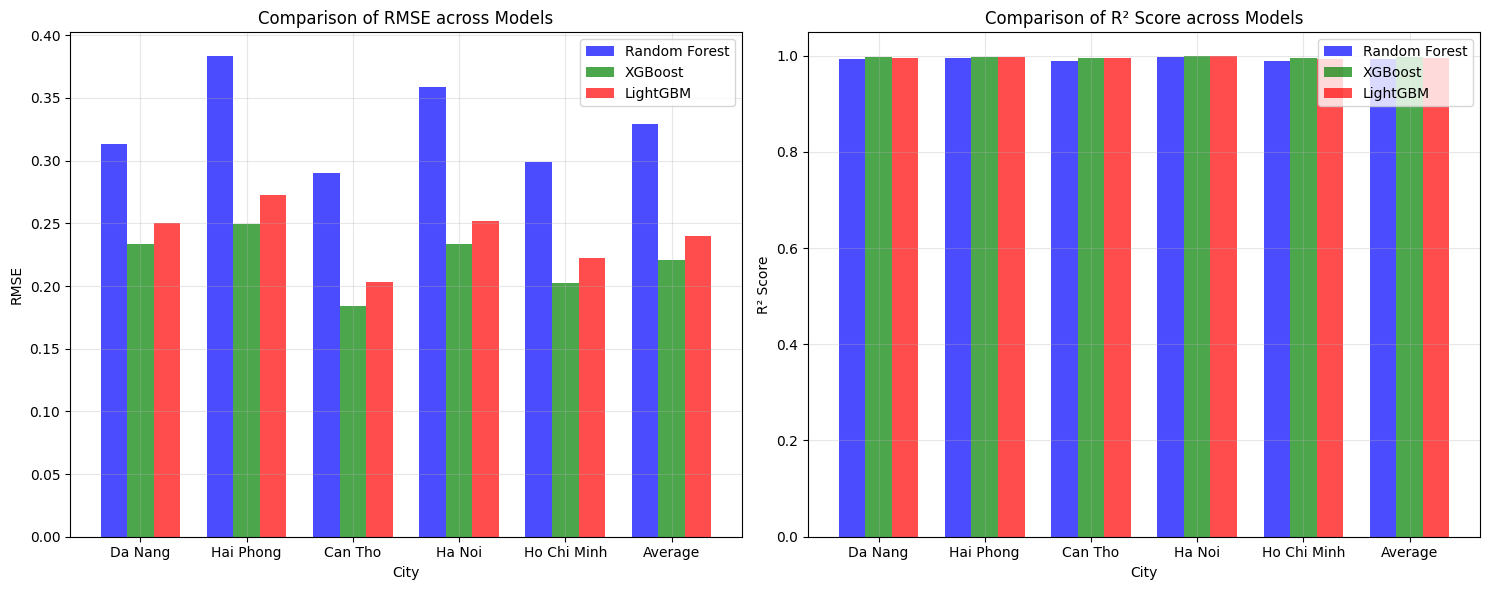


✓ Đã hoàn thành so sánh các mô hình


In [11]:
# ========== PHẦN 9: SO SÁNH MÔ HÌNH ==========
import builtins # Import builtins to access original min function

def compare_models():
    """
    So sánh hiệu suất của 3 mô hình
    """
    print("\n" + "="*80)
    print("SO SÁNH HIỆU SUẤT CÁC MÔ HÌNH")
    print("="*80)

    comparison_data = []

    for city in cities:
        comparison_data.append({
            'City': city,
            'RF_RMSE': rf_scores[city]['rmse'],
            'RF_R2': rf_scores[city]['r2'],
            'XGB_RMSE': xgb_scores[city]['rmse'],
            'XGB_R2': xgb_scores[city]['r2'],
            'LGB_RMSE': lgb_scores[city]['rmse'],
            'LGB_R2': lgb_scores[city]['r2']
        })

    comparison_df = pd.DataFrame(comparison_data)

    # Tính trung bình
    avg_row = {
        'City': 'AVERAGE',
        'RF_RMSE': comparison_df['RF_RMSE'].mean(),
        'RF_R2': comparison_df['RF_R2'].mean(),
        'XGB_RMSE': comparison_df['XGB_RMSE'].mean(),
        'XGB_R2': comparison_df['XGB_R2'].mean(),
        'LGB_RMSE': comparison_df['LGB_RMSE'].mean(),
        'LGB_R2': comparison_df['LGB_R2'].mean()
    }

    comparison_df = pd.concat([comparison_df, pd.DataFrame([avg_row])], ignore_index=True)

    print("\nBảng so sánh hiệu suất:")
    print("-" * 80)
    print(comparison_df.round(4).to_string(index=False))

    # Tìm mô hình tốt nhất cho từng thành phố
    print("\n" + "-"*80)
    print("MÔ HÌNH TỐT NHẤT CHO TỪNG THÀNH PHỐ:")
    print("-"*80)

    for city in cities:
        models_perf = {
            'Random Forest': rf_scores[city]['rmse'],
            'XGBoost': xgb_scores[city]['rmse'],
            'LightGBM': lgb_scores[city]['rmse']
        }

        best_model = builtins.min(models_perf, key=models_perf.get)
        best_rmse = models_perf[best_model]

        print(f"{city}: {best_model} (RMSE: {best_rmse:.4f})")

    # Vẽ biểu đồ so sánh
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # Biểu đồ RMSE
    cities_list = cities + ['Average']
    rf_rmse = [rf_scores[c]['rmse'] for c in cities] + [comparison_df['RF_RMSE'].iloc[-1]]
    xgb_rmse = [xgb_scores[c]['rmse'] for c in cities] + [comparison_df['XGB_RMSE'].iloc[-1]]
    lgb_rmse = [lgb_scores[c]['rmse'] for c in cities] + [comparison_df['LGB_RMSE'].iloc[-1]]

    x = np.arange(len(cities_list))
    width = 0.25

    axes[0].bar(x - width, rf_rmse, width, label='Random Forest', color='blue', alpha=0.7)
    axes[0].bar(x, xgb_rmse, width, label='XGBoost', color='green', alpha=0.7)
    axes[0].bar(x + width, lgb_rmse, width, label='LightGBM', color='red', alpha=0.7)

    axes[0].set_xlabel('City')
    axes[0].set_ylabel('RMSE')
    axes[0].set_title('Comparison of RMSE across Models')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(cities_list)
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Biểu đồ R²
    rf_r2 = [rf_scores[c]['r2'] for c in cities] + [comparison_df['RF_R2'].iloc[-1]]
    xgb_r2 = [xgb_scores[c]['r2'] for c in cities] + [comparison_df['XGB_R2'].iloc[-1]]
    lgb_r2 = [lgb_scores[c]['r2'] for c in cities] + [comparison_df['LGB_R2'].iloc[-1]]

    axes[1].bar(x - width, rf_r2, width, label='Random Forest', color='blue', alpha=0.7)
    axes[1].bar(x, xgb_r2, width, label='XGBoost', color='green', alpha=0.7)
    axes[1].bar(x + width, lgb_r2, width, label='LightGBM', color='red', alpha=0.7)

    axes[1].set_xlabel('City')
    axes[1].set_ylabel('R² Score')
    axes[1].set_title('Comparison of R² Score across Models')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(cities_list)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

    return comparison_df

# So sánh các mô hình
comparison_results = compare_models()
print("\n✓ Đã hoàn thành so sánh các mô hình")


LƯU MODEL TỐT NHẤT VÀ CHUẨN BỊ DỰ BÁO 7 NGÀY

Da Nang:
  Model tốt nhất: XGBoost
  RMSE: 0.2339
  Số lượng features: 28
  Đã lưu: best_model_Da_Nang.pkl

Hai Phong:
  Model tốt nhất: XGBoost
  RMSE: 0.2491
  Số lượng features: 28
  Đã lưu: best_model_Hai_Phong.pkl

Can Tho:
  Model tốt nhất: XGBoost
  RMSE: 0.1843
  Số lượng features: 28
  Đã lưu: best_model_Can_Tho.pkl

Ha Noi:
  Model tốt nhất: XGBoost
  RMSE: 0.2334
  Số lượng features: 28
  Đã lưu: best_model_Ha_Noi.pkl

Ho Chi Minh:
  Model tốt nhất: XGBoost
  RMSE: 0.2021
  Số lượng features: 28
  Đã lưu: best_model_Ho_Chi_Minh.pkl

✓ Đã lưu tổng hợp model tốt nhất vào: best_models_summary.csv

BẮT ĐẦU DỰ BÁO 7 NGÀY CHO TẤT CẢ THÀNH PHỐ

ĐANG XỬ LÝ: Da Nang

DỰ BÁO 7 NGÀY - Da Nang
Sử dụng model: XGBoost

Thành phố: Da Nang
Ngày cuối cùng trong dữ liệu: 2026-01-31 16:00:00
Ngày bắt đầu dự báo: 2026-01-31 17:00:00
Ngày kết thúc dự báo: 2026-02-07 16:00:00
Số giờ cần dự báo: 168


/tmp/ipython-input-3854703957.py:96: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  future_dates = pd.date_range(


  Đã dự báo xong ngày 1: 22.0°C
  Đã dự báo xong ngày 2: 22.0°C
  Đã dự báo xong ngày 3: 22.0°C
  Đã dự báo xong ngày 4: 22.0°C
  Đã dự báo xong ngày 5: 22.0°C
  Đã dự báo xong ngày 6: 22.0°C
  Đã dự báo xong ngày 7: 22.0°C

📊 KẾT QUẢ DỰ BÁO Da Nang:
--------------------------------------------------
             Min (°C)  Max (°C)   Avg (°C)  Std (°C)
date                                                
2026-01-31  21.700001      22.1  21.799999       0.1
2026-02-01  21.700001      22.5  22.100000       0.3
2026-02-02  21.700001      22.5  22.000000       0.3
2026-02-03  21.700001      22.5  22.000000       0.3
2026-02-04  21.700001      22.5  22.000000       0.3
2026-02-05  21.700001      22.5  22.000000       0.3
2026-02-06  21.700001      22.5  22.000000       0.3
2026-02-07  21.700001      22.4  22.000000       0.2

📈 THỐNG KÊ TỔNG:
  Nhiệt độ trung bình: 22.0°C
  Nhiệt độ thấp nhất: 21.7°C
  Nhiệt độ cao nhất: 22.5°C
  Biên độ nhiệt: 0.9°C

💾 Đã lưu dự báo vào: 7day_forecast_Da_N

/tmp/ipython-input-3854703957.py:96: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  future_dates = pd.date_range(


  Đã dự báo xong ngày 1: 19.4°C
  Đã dự báo xong ngày 2: 19.5°C
  Đã dự báo xong ngày 3: 19.5°C
  Đã dự báo xong ngày 4: 19.5°C
  Đã dự báo xong ngày 5: 19.5°C
  Đã dự báo xong ngày 6: 19.5°C
  Đã dự báo xong ngày 7: 19.5°C

📊 KẾT QUẢ DỰ BÁO Hai Phong:
--------------------------------------------------
             Min (°C)  Max (°C)  Avg (°C)  Std (°C)
date                                               
2026-01-31  18.700001      19.6      19.1       0.3
2026-02-01  19.100000      20.0      19.5       0.3
2026-02-02  18.900000      20.0      19.5       0.4
2026-02-03  18.900000      20.0      19.5       0.4
2026-02-04  18.900000      20.1      19.5       0.4
2026-02-05  18.900000      20.1      19.5       0.4
2026-02-06  18.900000      20.0      19.5       0.4
2026-02-07  18.900000      19.9      19.5       0.4

📈 THỐNG KÊ TỔNG:
  Nhiệt độ trung bình: 19.5°C
  Nhiệt độ thấp nhất: 18.7°C
  Nhiệt độ cao nhất: 20.1°C
  Biên độ nhiệt: 1.4°C

💾 Đã lưu dự báo vào: 7day_forecast_Hai_Phong.cs

...

  Đã dự báo xong ngày 1: 25.5°C
  Đã dự báo xong ngày 2: 25.7°C
  Đã dự báo xong ngày 3: 25.7°C
  Đã dự báo xong ngày 4: 25.7°C
  Đã dự báo xong ngày 5: 25.7°C
  Đã dự báo xong ngày 6: 25.7°C
  Đã dự báo xong ngày 7: 25.7°C

📊 KẾT QUẢ DỰ BÁO Can Tho:
--------------------------------------------------
            Min (°C)   Max (°C)   Avg (°C)  Std (°C)
date                                                
2026-01-31      24.6  25.500000  25.000000       0.3
2026-02-01      25.1  26.299999  25.700001       0.5
2026-02-02      25.1  26.299999  25.700001       0.4
2026-02-03      25.0  26.299999  25.700001       0.5
2026-02-04      25.0  26.299999  25.700001       0.5
2026-02-05      25.0  26.299999  25.700001       0.5
2026-02-06      25.0  26.299999  25.700001       0.5
2026-02-07      25.0  26.299999  25.799999       0.5

📈 THỐNG KÊ TỔNG:
  Nhiệt độ trung bình: 25.7°C
  Nhiệt độ thấp nhất: 24.6°C
  Nhiệt độ cao nhất: 26.3°C
  Biên độ nhiệt: 1.7°C

💾 Đã lưu dự báo vào: 7day_forecast_Can_

/tmp/ipython-input-3854703957.py:96: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  future_dates = pd.date_range(


  Đã dự báo xong ngày 1: 19.6°C
  Đã dự báo xong ngày 2: 19.7°C
  Đã dự báo xong ngày 3: 19.8°C
  Đã dự báo xong ngày 4: 19.8°C
  Đã dự báo xong ngày 5: 19.8°C
  Đã dự báo xong ngày 6: 19.8°C
  Đã dự báo xong ngày 7: 19.8°C

📊 KẾT QUẢ DỰ BÁO Ha Noi:
--------------------------------------------------
            Min (°C)   Max (°C)   Avg (°C)  Std (°C)
date                                                
2026-01-31      19.0  19.700001  19.200001       0.2
2026-02-01      19.0  20.400000  19.700001       0.5
2026-02-02      19.0  20.500000  19.799999       0.5
2026-02-03      19.0  20.500000  19.799999       0.5
2026-02-04      19.0  20.500000  19.799999       0.5
2026-02-05      19.0  20.500000  19.799999       0.5
2026-02-06      19.0  20.500000  19.799999       0.5
2026-02-07      19.0  20.299999  19.799999       0.5

📈 THỐNG KÊ TỔNG:
  Nhiệt độ trung bình: 19.7°C
  Nhiệt độ thấp nhất: 19.0°C
  Nhiệt độ cao nhất: 20.5°C
  Biên độ nhiệt: 1.5°C

💾 Đã lưu dự báo vào: 7day_forecast_Ha_No

/tmp/ipython-input-3854703957.py:96: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  future_dates = pd.date_range(


  Đã dự báo xong ngày 1: 27.1°C
  Đã dự báo xong ngày 2: 27.2°C
  Đã dự báo xong ngày 3: 27.3°C
  Đã dự báo xong ngày 4: 27.3°C
  Đã dự báo xong ngày 5: 27.3°C
  Đã dự báo xong ngày 6: 27.3°C
  Đã dự báo xong ngày 7: 27.3°C

📊 KẾT QUẢ DỰ BÁO Ho Chi Minh:
--------------------------------------------------
             Min (°C)   Max (°C)   Avg (°C)  Std (°C)
date                                                 
2026-01-31  25.900000  26.900000  26.200001       0.4
2026-02-01  25.900000  28.500000  27.200001       0.9
2026-02-02  26.200001  28.200001  27.200001       0.9
2026-02-03  26.100000  28.299999  27.299999       0.9
2026-02-04  26.100000  28.299999  27.299999       0.9
2026-02-05  26.100000  28.299999  27.299999       0.9
2026-02-06  26.100000  28.299999  27.299999       0.9
2026-02-07  26.100000  28.299999  27.400000       0.9

📈 THỐNG KÊ TỔNG:
  Nhiệt độ trung bình: 27.2°C
  Nhiệt độ thấp nhất: 25.9°C
  Nhiệt độ cao nhất: 28.5°C
  Biên độ nhiệt: 2.6°C

💾 Đã lưu dự báo vào: 7day

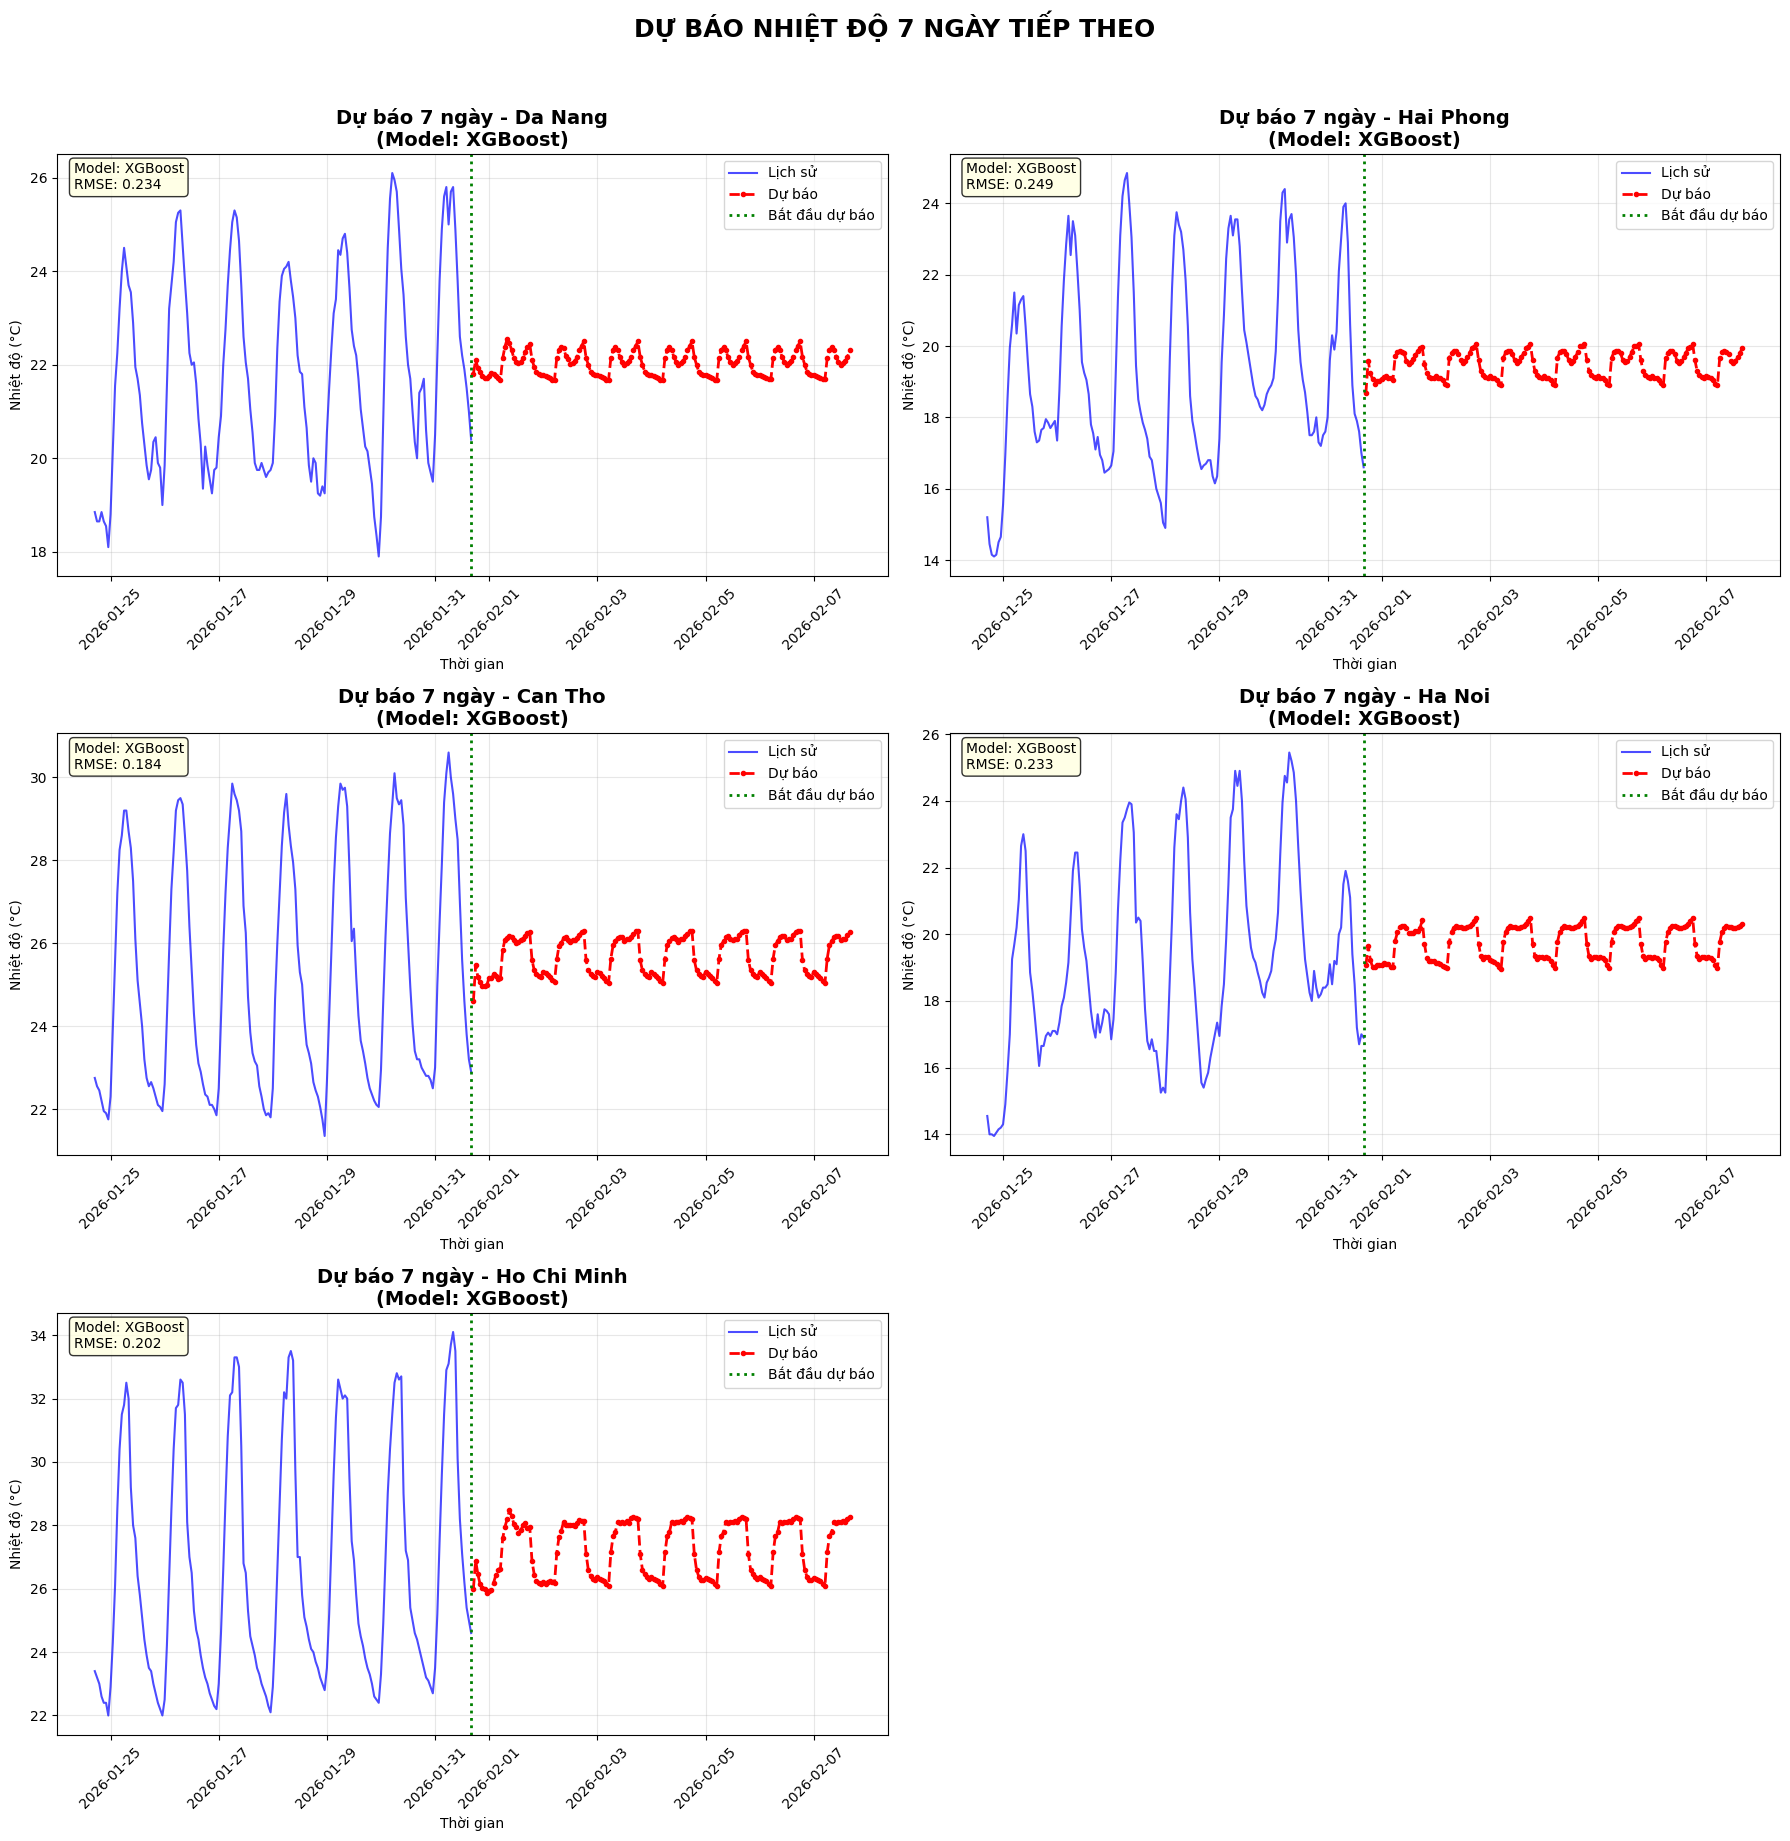

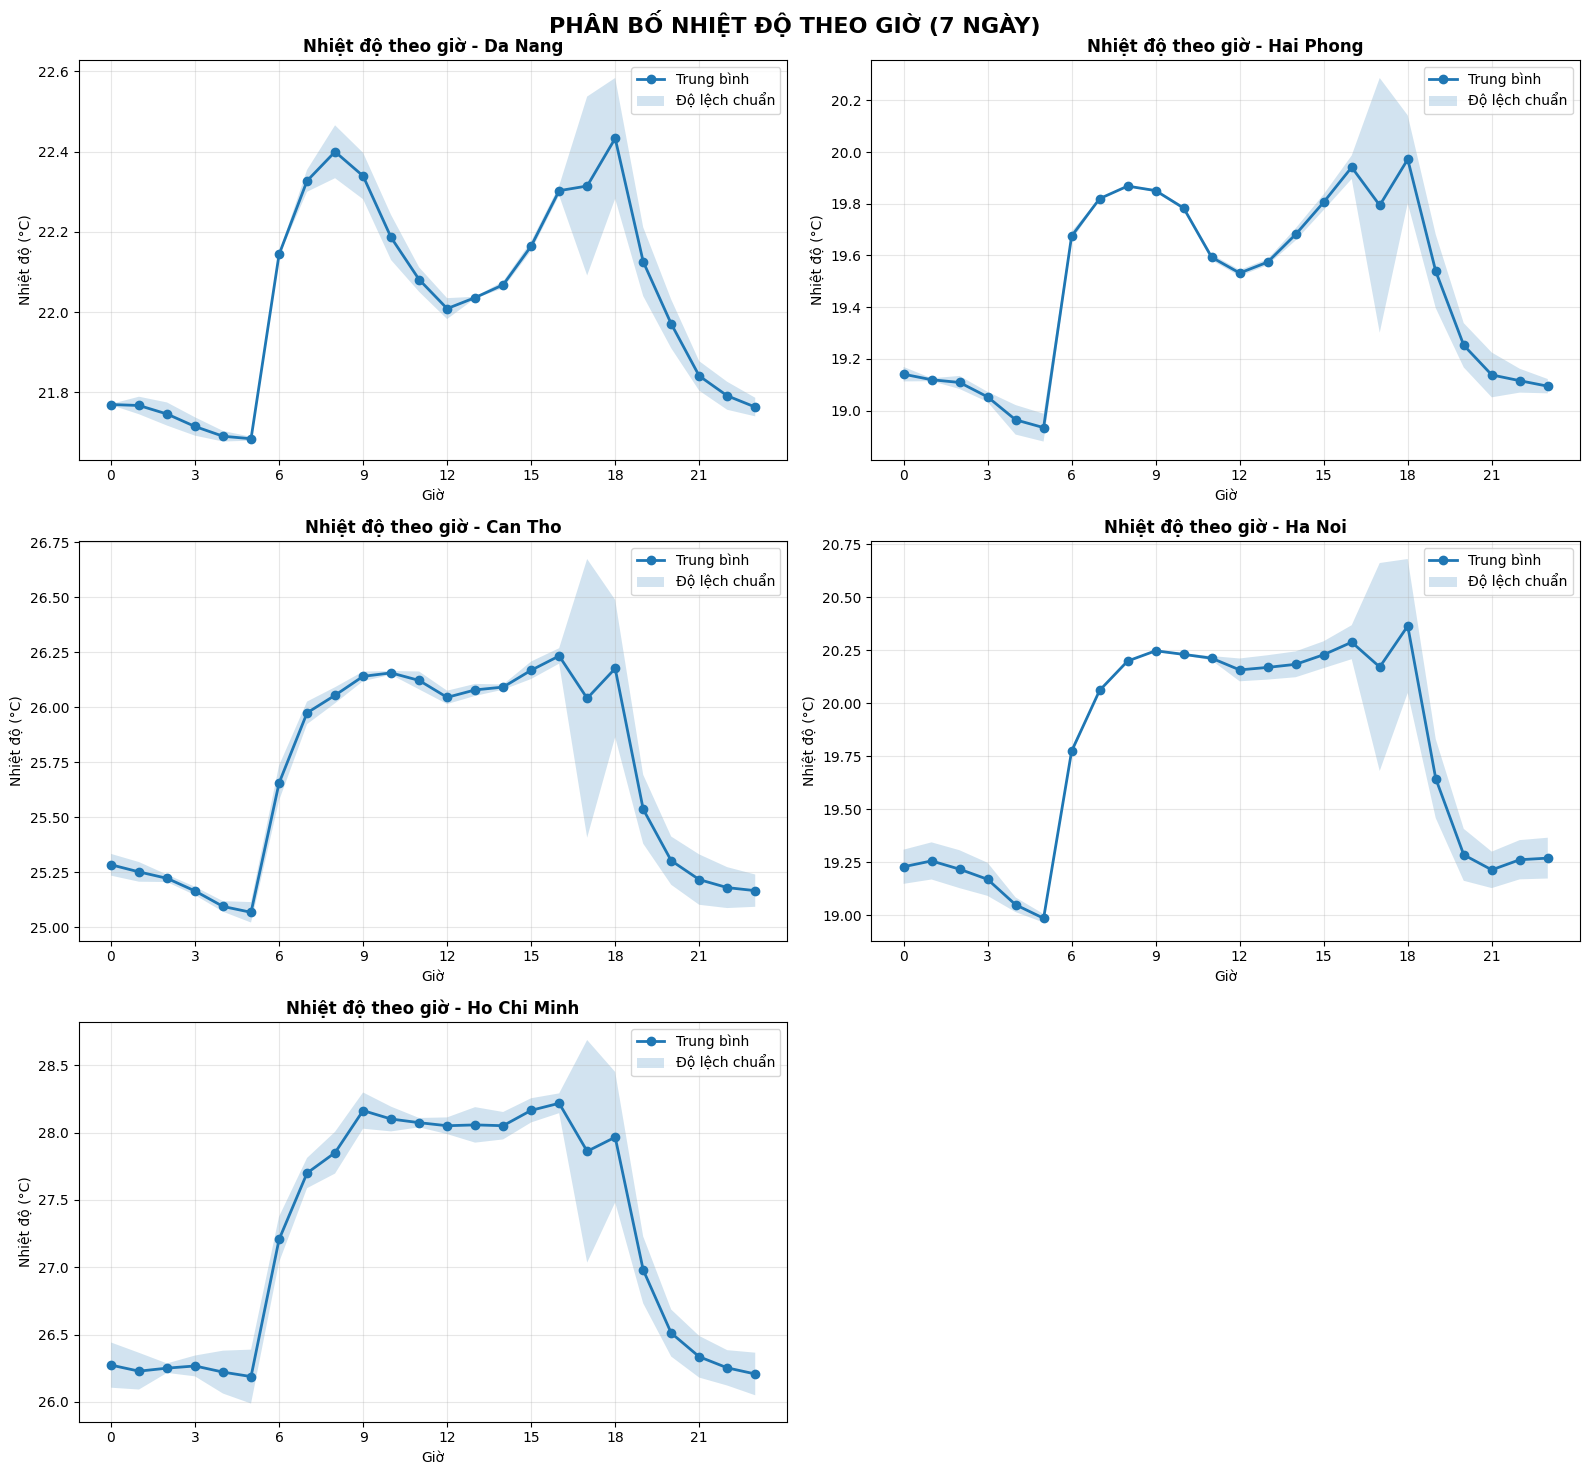

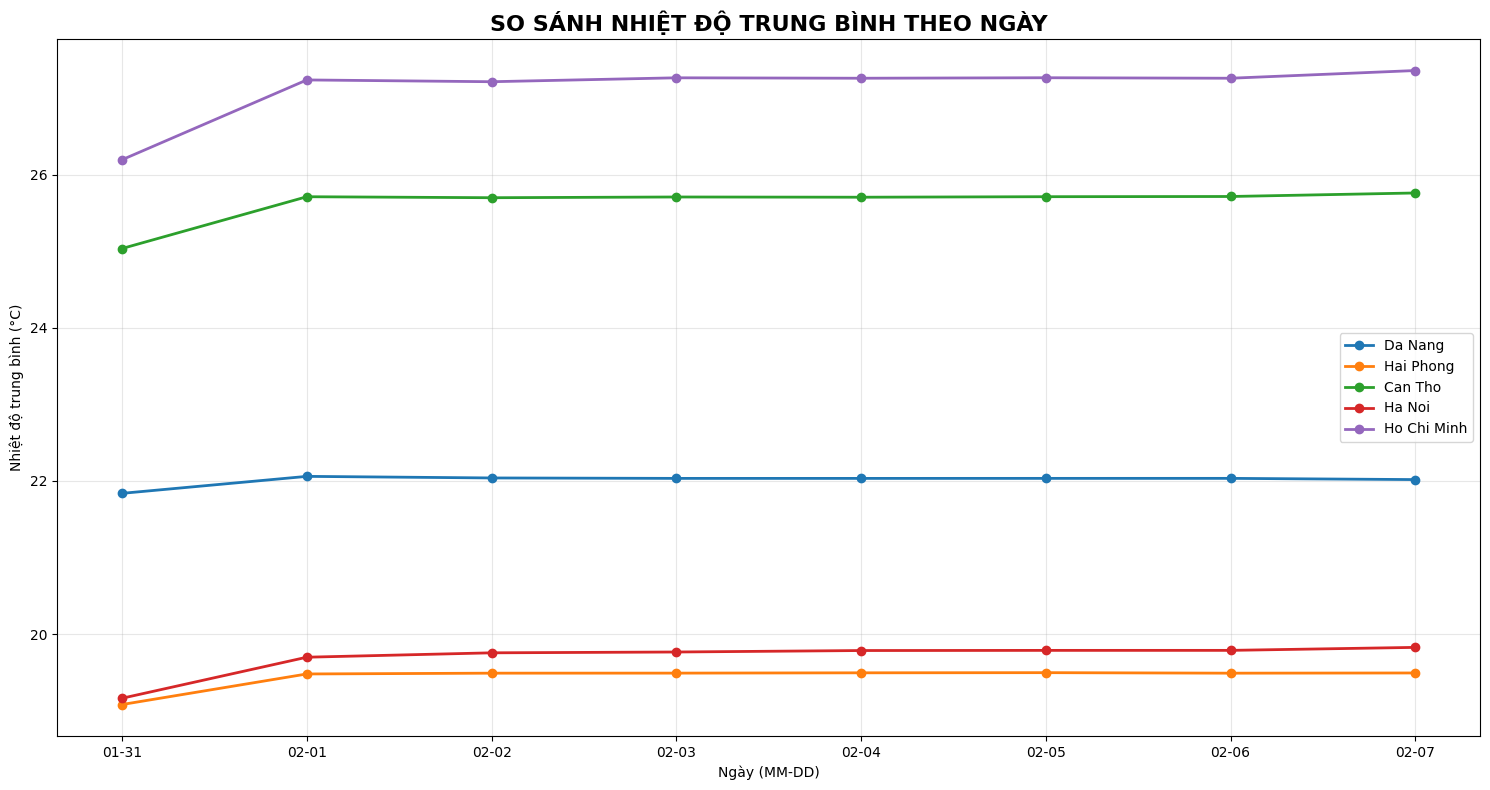

✓ Đã tạo xong toàn bộ biểu đồ cho 5 thành phố

TẠO BÁO CÁO TỔNG HỢP
✓ Đã lưu báo cáo tổng hợp: final_report/summary_report.csv
✓ Đã lưu metadata: final_report/metadata.json
✓ Đã tạo báo cáo chi tiết: final_report/final_report.txt

📋 BÁO CÁO TÓM TẮT

🏙️ THÀNH PHỐ ĐÃ DỰ BÁO:
  • Da Nang: 22.0°C (Model: XGBoost)
  • Hai Phong: 19.5°C (Model: XGBoost)
  • Can Tho: 25.7°C (Model: XGBoost)
  • Ha Noi: 19.7°C (Model: XGBoost)
  • Ho Chi Minh: 27.2°C (Model: XGBoost)

🏆 MODEL TỐT NHẤT ĐƯỢC CHỌN:
  • XGBoost: 5 thành phố

📈 XU HƯỚNG NHIỆT ĐỘ:
  • Da Nang: ➡️ ỔN ĐỊNH
  • Hai Phong: ➡️ ỔN ĐỊNH
  • Can Tho: ➡️ ỔN ĐỊNH
  • Ha Noi: ➡️ ỔN ĐỊNH
  • Ho Chi Minh: ➡️ ỔN ĐỊNH

🎉 QUY TRÌNH HOÀN TẤT!
Đã thực hiện thành công:
  1. Huấn luyện 3 mô hình (Random Forest, XGBoost, LightGBM)
  2. So sánh và chọn model tốt nhất cho từng thành phố
  3. Dự báo nhiệt độ 7 ngày tiếp theo
  4. Trực quan hóa kết quả
  5. Lưu báo cáo tổng hợp

Các file kết quả đã được lưu trong thư mục hiện tại và thư mục 'final_report/'


In [13]:
# ========== PHẦN 10: LƯU MODEL TỐT NHẤT VÀ CHUẨN BỊ DỰ BÁO ==========
def save_best_models_and_prepare_forecast():
    """
    Lưu model tốt nhất cho từng thành phố và chuẩn bị cho dự báo 7 ngày
    """
    print("\n" + "="*80)
    print("LƯU MODEL TỐT NHẤT VÀ CHUẨN BỊ DỰ BÁO 7 NGÀY")
    print("="*80)

    best_models_info = {}

    for city in cities:
        # So sánh RMSE của các model
        rf_rmse = rf_scores[city]['rmse']
        xgb_rmse = xgb_scores[city]['rmse']
        lgb_rmse = lgb_scores[city]['rmse']

        # Tìm model có RMSE thấp nhất (tốt nhất)
        if rf_rmse <= xgb_rmse and rf_rmse <= lgb_rmse:
            best_model = rf_models[city]
            best_model_name = "Random Forest"
            best_score = rf_rmse
            best_features = rf_features[city]
        elif xgb_rmse <= rf_rmse and xgb_rmse <= lgb_rmse:
            best_model = xgb_models[city]
            best_model_name = "XGBoost"
            best_score = xgb_rmse
            best_features = xgb_features[city]
        else:
            best_model = lgb_models[city]
            best_model_name = "LightGBM"
            best_score = lgb_rmse
            best_features = lgb_features[city]

        # Lưu thông tin model tốt nhất
        best_models_info[city] = {
            'model': best_model,
            'model_name': best_model_name,
            'features': best_features,
            'rmse': best_score,
            'model_type': type(best_model).__name__
        }

        print(f"\n{city}:")
        print(f"  Model tốt nhất: {best_model_name}")
        print(f"  RMSE: {best_score:.4f}")
        print(f"  Số lượng features: {len(best_features)}")

        # Lưu model tốt nhất
        best_model_filename = f"best_model_{city.replace(' ', '_')}.pkl"
        joblib.dump({
            'model': best_model,
            'model_name': best_model_name,
            'features': best_features,
            'city': city,
            'rmse': best_score
        }, best_model_filename)

        print(f"  Đã lưu: {best_model_filename}")

    # Lưu tổng hợp model tốt nhất
    best_models_summary = pd.DataFrame([
        {
            'City': city,
            'Best_Model': info['model_name'],
            'RMSE': info['rmse'],
            'Features_Count': len(info['features']),
            'Model_Type': info['model_type']
        }
        for city, info in best_models_info.items()
    ])

    best_models_summary.to_csv('best_models_summary.csv', index=False)
    print("\n✓ Đã lưu tổng hợp model tốt nhất vào: best_models_summary.csv")

    return best_models_info

# Lưu model tốt nhất
best_models_info = save_best_models_and_prepare_forecast()

# ========== PHẦN 11: TẠO FEATURES CHO DỰ BÁO 7 NGÀY ==========
def prepare_7day_forecast_features(city_data, city_name, n_days=7):
    """
    Chuẩn bị features cho dự báo 7 ngày tiếp theo
    """
    # Lấy dữ liệu đầy đủ của thành phố
    full_data = city_data[city_name]['full'].toPandas().sort_values('timestamp')

    # Lấy timestamp cuối cùng
    last_timestamp = full_data['timestamp'].iloc[-1]

    print(f"\nThành phố: {city_name}")
    print(f"Ngày cuối cùng trong dữ liệu: {last_timestamp}")

    # Tạo future timestamps (7 ngày * 24 giờ = 168 giờ)
    future_dates = pd.date_range(
        start=last_timestamp + pd.Timedelta(hours=1),
        periods=n_days * 24,
        freq='H'
    )

    future_df = pd.DataFrame({
        'timestamp': future_dates,
        'city': city_name
    })

    # Tạo các đặc trưng thời gian cơ bản
    future_df['hour'] = future_df['timestamp'].dt.hour
    future_df['day_of_week'] = future_df['timestamp'].dt.dayofweek + 1
    future_df['month'] = future_df['timestamp'].dt.month
    future_df['day_of_year'] = future_df['timestamp'].dt.dayofyear
    future_df['year'] = future_df['timestamp'].dt.year

    # Đặc trưng cyclic
    future_df['hour_sin'] = np.sin(2 * np.pi * future_df['hour'] / 24)
    future_df['hour_cos'] = np.cos(2 * np.pi * future_df['hour'] / 24)
    future_df['dow_sin'] = np.sin(2 * np.pi * future_df['day_of_week'] / 7)
    future_df['dow_cos'] = np.cos(2 * np.pi * future_df['day_of_week'] / 7)
    future_df['month_sin'] = np.sin(2 * np.pi * future_df['month'] / 12)
    future_df['month_cos'] = np.cos(2 * np.pi * future_df['month'] / 12)

    # Mã hóa thành phố
    city_mapping = {"Da Nang": 0, "Hai Phong": 1, "Can Tho": 2, "Ha Noi": 3, "Ho Chi Minh": 4}
    future_df['city_code'] = city_mapping[city_name]

    print(f"Ngày bắt đầu dự báo: {future_dates[0]}")
    print(f"Ngày kết thúc dự báo: {future_dates[-1]}")
    print(f"Số giờ cần dự báo: {len(future_dates)}")

    return future_df, full_data

# ========== PHẦN 12: DỰ BÁO 7 NGÀY VỚI MODEL TỐT NHẤT ==========
def forecast_7days_with_best_model(best_model_info, city_data, city_name):
    """
    Dự báo 7 ngày tiếp theo với model tốt nhất
    """
    print(f"\n{'='*60}")
    print(f"DỰ BÁO 7 NGÀY - {city_name}")
    print(f"{'='*60}")

    model = best_model_info['model']
    model_name = best_model_info['model_name']
    required_features = best_model_info['features']

    print(f"Sử dụng model: {model_name}")

    # Chuẩn bị features cho tương lai
    future_df, historical_data = prepare_7day_forecast_features(city_data, city_name)

    # Lấy dữ liệu lịch sử để tạo lag features
    temp_history = historical_data['temperature'].values.tolist()
    weather_history = historical_data.iloc[-168:]  # Lấy 7 ngày gần nhất

    predictions = []

    # Dự báo từng giờ một (recursive forecasting)
    for i in range(len(future_df)):
        # Tạo bản ghi cho giờ hiện tại
        current_record = future_df.iloc[i].copy()

        # Thêm các đặc trưng thời tiết (sử dụng giá trị trung bình/history)
        current_record['humidity'] = weather_history['humidity'].mean()
        current_record['apparent_temp'] = weather_history['apparent_temp'].mean()
        current_record['weather_code'] = weather_history['weather_code'].mode()[0] if len(weather_history['weather_code'].mode()) > 0 else 1
        current_record['pressure'] = weather_history['pressure'].mean()
        current_record['rain'] = weather_history['rain'].mean()
        current_record['wind_speed'] = weather_history['wind_speed'].mean()
        current_record['wind_direction'] = weather_history['wind_direction'].mean()
        current_record['wind_gusts'] = weather_history['wind_gusts'].mean()

        # Solar radiation dựa trên giờ trong ngày
        hour = current_record['hour']
        if 6 <= hour <= 18:
            current_record['solar_radiation'] = 800 - abs(12 - hour) * 50
        else:
            current_record['solar_radiation'] = 0

        current_record['cloud_cover'] = weather_history['cloud_cover'].mean()
        current_record['is_day'] = 1 if 6 <= hour <= 18 else 0

        # Thêm lag features
        lag_periods = [1, 2, 3, 24, 48, 168]
        for lag in lag_periods:
            lag_col = f'temperature_lag_{lag}'
            if lag_col in required_features:
                if len(temp_history) >= lag:
                    current_record[lag_col] = temp_history[-lag]
                else:
                    current_record[lag_col] = np.mean(temp_history) if temp_history else 25

        # Thêm moving averages
        ma_windows = {
            'temperature_ma_6h': 6,
            'temperature_ma_12h': 12,
            'temperature_ma_24h': 24,
            'temperature_ma_7d': 168
        }

        for ma_col, window in ma_windows.items():
            if ma_col in required_features:
                if len(temp_history) >= window:
                    current_record[ma_col] = np.mean(temp_history[-window:])
                else:
                    current_record[ma_col] = np.mean(temp_history) if temp_history else 25

        # Chuẩn bị dữ liệu cho prediction
        features_df = pd.DataFrame([current_record])

        # Đảm bảo tất cả features cần thiết đều có
        for feature in required_features:
            if feature not in features_df.columns:
                features_df[feature] = 0

        # Dự đoán nhiệt độ
        try:
            # Kiểm tra loại model và dự đoán phù hợp
            if hasattr(model, 'predict'):
                X_pred = features_df[required_features]

                # Xử lý đặc biệt cho XGBoost native model
                if model_name == 'XGBoost' and not hasattr(model, 'feature_importances_'):
                    # Đây là native xgb.Booster
                    import xgboost as xgb
                    dmatrix = xgb.DMatrix(X_pred)
                    pred_temp = model.predict(dmatrix)[0]
                else:
                    # Sklearn-compatible model
                    pred_temp = model.predict(X_pred)[0]
            else:
                pred_temp = np.mean(temp_history[-24:]) if temp_history else 25

        except Exception as e:
            print(f"  Lỗi khi dự đoán: {e}")
            pred_temp = np.mean(temp_history[-24:]) if temp_history else 25

        predictions.append(pred_temp)

        # Cập nhật lịch sử
        temp_history.append(pred_temp)

        # Hiển thị tiến trình
        if (i + 1) % 24 == 0:
            day_num = (i + 1) // 24
            avg_temp_day = np.mean(predictions[-24:])
            print(f"  Đã dự báo xong ngày {day_num}: {avg_temp_day:.1f}°C")

    # Thêm predictions vào dataframe
    future_df['predicted_temperature'] = predictions

    return future_df

# ========== PHẦN 13: THỰC HIỆN DỰ BÁO CHO TẤT CẢ THÀNH PHỐ ==========
print("\n" + "="*80)
print("BẮT ĐẦU DỰ BÁO 7 NGÀY CHO TẤT CẢ THÀNH PHỐ")
print("="*80)

all_7day_forecasts = {}

for city in cities:
    try:
        print(f"\n{'='*50}")
        print(f"ĐANG XỬ LÝ: {city}")
        print(f"{'='*50}")

        forecast_df = forecast_7days_with_best_model(best_models_info[city], city_data, city)
        all_7day_forecasts[city] = forecast_df

        # Hiển thị kết quả theo ngày
        print(f"\n📊 KẾT QUẢ DỰ BÁO {city}:")
        print("-" * 50)

        forecast_df['date'] = forecast_df['timestamp'].dt.date
        daily_summary = forecast_df.groupby('date').agg({
            'predicted_temperature': ['min', 'max', 'mean', 'std']
        }).round(1)

        daily_summary.columns = ['Min (°C)', 'Max (°C)', 'Avg (°C)', 'Std (°C)']
        print(daily_summary.to_string())

        # Tính toán thống kê tổng
        avg_temp = forecast_df['predicted_temperature'].mean()
        min_temp = forecast_df['predicted_temperature'].min()
        max_temp = forecast_df['predicted_temperature'].max()
        temp_range = max_temp - min_temp

        print(f"\n📈 THỐNG KÊ TỔNG:")
        print(f"  Nhiệt độ trung bình: {avg_temp:.1f}°C")
        print(f"  Nhiệt độ thấp nhất: {min_temp:.1f}°C")
        print(f"  Nhiệt độ cao nhất: {max_temp:.1f}°C")
        print(f"  Biên độ nhiệt: {temp_range:.1f}°C")

        # Lưu kết quả dự báo
        output_file = f"7day_forecast_{city.replace(' ', '_')}.csv"
        forecast_df[['timestamp', 'hour', 'predicted_temperature']].to_csv(output_file, index=False)
        print(f"\n💾 Đã lưu dự báo vào: {output_file}")

    except Exception as e:
        print(f"❌ Lỗi khi dự báo cho {city}: {e}")
        continue

print("\n✓ Đã hoàn thành dự báo cho tất cả thành phố")

# ========== PHẦN 14: TRỰC QUAN HÓA KẾT QUẢ DỰ BÁO ==========
def visualize_7day_forecasts(all_forecasts, city_data):
    """
    Trực quan hóa kết quả dự báo 7 ngày (tự động theo số thành phố)
    """
    import math
    import matplotlib.pyplot as plt
    import numpy as np

    print("\n" + "="*80)
    print("TRỰC QUAN HÓA KẾT QUẢ DỰ BÁO")
    print("="*80)

    # =========================
    # BIỂU ĐỒ 1: DỰ BÁO 7 NGÀY
    # =========================
    valid_cities = [city for city in cities if city in all_forecasts]
    n_cities = len(valid_cities)

    cols = 2
    rows = math.ceil(n_cities / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 6))
    axes = axes.flatten()

    for idx, city in enumerate(valid_cities):
        ax = axes[idx]

        # Lấy dữ liệu lịch sử (7 ngày cuối)
        historical_data = city_data[city]['full'].toPandas().sort_values('timestamp')
        historical_data = historical_data.tail(7 * 24)

        # Lấy dữ liệu dự báo
        forecast_data = all_forecasts[city]

        # Vẽ biểu đồ
        ax.plot(
            historical_data['timestamp'],
            historical_data['temperature'],
            label='Lịch sử',
            color='blue',
            alpha=0.7,
            linewidth=1.5
        )

        ax.plot(
            forecast_data['timestamp'],
            forecast_data['predicted_temperature'],
            label='Dự báo',
            color='red',
            linestyle='--',
            linewidth=2,
            marker='o',
            markersize=3
        )

        # Đường phân cách
        last_time = historical_data['timestamp'].iloc[-1]
        ax.axvline(
            x=last_time,
            color='green',
            linestyle=':',
            linewidth=2,
            label='Bắt đầu dự báo'
        )

        ax.set_title(
            f'Dự báo 7 ngày - {city}\n(Model: {best_models_info[city]["model_name"]})',
            fontsize=14,
            fontweight='bold'
        )

        ax.set_xlabel('Thời gian')
        ax.set_ylabel('Nhiệt độ (°C)')
        ax.legend()
        ax.grid(True, alpha=0.3)
        ax.tick_params(axis='x', rotation=45)

        # Thông tin model
        info = (
            f"Model: {best_models_info[city]['model_name']}\n"
            f"RMSE: {best_models_info[city]['rmse']:.3f}"
        )

        ax.text(
            0.02, 0.98, info,
            transform=ax.transAxes,
            verticalalignment='top',
            fontsize=10,
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8)
        )

    # Ẩn subplot dư (nếu có)
    for i in range(n_cities, len(axes)):
        axes[i].axis('off')

    plt.suptitle(
        'DỰ BÁO NHIỆT ĐỘ 7 NGÀY TIẾP THEO',
        fontsize=18,
        fontweight='bold',
        y=1.02
    )

    plt.tight_layout()
    plt.savefig('7day_temperature_forecasts_all_cities.png', dpi=300, bbox_inches='tight')
    plt.show()

    # =========================================
    # BIỂU ĐỒ 2: NHIỆT ĐỘ THEO GIỜ TRONG NGÀY
    # =========================================
    fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 5))
    axes = axes.flatten()

    for idx, city in enumerate(valid_cities):
        ax = axes[idx]
        forecast_data = all_forecasts[city]

        hourly_avg = forecast_data.groupby('hour')['predicted_temperature'].mean()
        hourly_std = forecast_data.groupby('hour')['predicted_temperature'].std()

        hours = range(24)
        avg_temps = [hourly_avg.get(h, np.nan) for h in hours]
        std_temps = [hourly_std.get(h, 0) for h in hours]

        ax.plot(hours, avg_temps, marker='o', linewidth=2, label='Trung bình')
        ax.fill_between(
            hours,
            np.array(avg_temps) - np.array(std_temps),
            np.array(avg_temps) + np.array(std_temps),
            alpha=0.2,
            label='Độ lệch chuẩn'
        )

        ax.set_title(f'Nhiệt độ theo giờ - {city}', fontweight='bold')
        ax.set_xlabel('Giờ')
        ax.set_ylabel('Nhiệt độ (°C)')
        ax.set_xticks(range(0, 24, 3))
        ax.grid(True, alpha=0.3)
        ax.legend()

    for i in range(n_cities, len(axes)):
        axes[i].axis('off')

    plt.suptitle(
        'PHÂN BỐ NHIỆT ĐỘ THEO GIỜ (7 NGÀY)',
        fontsize=16,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.savefig('hourly_temperature_distribution_7days.png', dpi=300, bbox_inches='tight')
    plt.show()

    # =========================================
    # BIỂU ĐỒ 3: SO SÁNH GIỮA CÁC THÀNH PHỐ
    # =========================================
    fig, ax = plt.subplots(figsize=(15, 8))
    colors = plt.cm.tab10.colors  # đủ màu cho ≥10 thành phố

    for idx, city in enumerate(valid_cities):
        forecast_data = all_forecasts[city]
        forecast_data['date_str'] = forecast_data['timestamp'].dt.strftime('%m-%d')
        daily_avg = forecast_data.groupby('date_str')['predicted_temperature'].mean()

        ax.plot(
            daily_avg.index,
            daily_avg.values,
            marker='o',
            linewidth=2,
            color=colors[idx],
            label=city
        )

    ax.set_title(
        'SO SÁNH NHIỆT ĐỘ TRUNG BÌNH THEO NGÀY',
        fontsize=16,
        fontweight='bold'
    )

    ax.set_xlabel('Ngày (MM-DD)')
    ax.set_ylabel('Nhiệt độ trung bình (°C)')
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.savefig('city_comparison_7days.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("✓ Đã tạo xong toàn bộ biểu đồ cho", n_cities, "thành phố")


# Trực quan hóa kết quả
visualize_7day_forecasts(all_7day_forecasts, city_data)

# ========== PHẦN 15: LƯU BÁO CÁO TỔNG HỢP ==========
def save_final_report(all_forecasts, best_models_info):
    """
    Lưu báo cáo tổng hợp cuối cùng
    """
    print("\n" + "="*80)
    print("TẠO BÁO CÁO TỔNG HỢP")
    print("="*80)

    import json
    from datetime import datetime

    # Tạo thư mục lưu trữ
    import os
    os.makedirs('final_report', exist_ok=True)

    # 1. Lưu thông tin tổng hợp
    summary_data = []

    for city in cities:
        if city not in all_forecasts:
            continue

        forecast_data = all_forecasts[city]
        model_info = best_models_info[city]

        # Tính toán các chỉ số
        avg_temp = forecast_data['predicted_temperature'].mean()
        min_temp = forecast_data['predicted_temperature'].min()
        max_temp = forecast_data['predicted_temperature'].max()
        temp_range = max_temp - min_temp

        # Phân tích xu hướng
        first_3_days = forecast_data.iloc[:72]['predicted_temperature'].mean()
        last_3_days = forecast_data.iloc[-72:]['predicted_temperature'].mean()

        if last_3_days > first_3_days + 0.5:
            trend = "TĂNG"
            trend_icon = "📈"
        elif last_3_days < first_3_days - 0.5:
            trend = "GIẢM"
            trend_icon = "📉"
        else:
            trend = "ỔN ĐỊNH"
            trend_icon = "➡️"

        summary_data.append({
            'Thành phố': city,
            'Model tốt nhất': model_info['model_name'],
            'RMSE model': round(model_info['rmse'], 3),
            'Nhiệt độ TB 7 ngày': round(avg_temp, 1),
            'Nhiệt độ thấp nhất': round(min_temp, 1),
            'Nhiệt độ cao nhất': round(max_temp, 1),
            'Biên độ nhiệt': round(temp_range, 1),
            'Xu hướng': f"{trend_icon} {trend}",
            'Nhiệt độ đầu kỳ': round(first_3_days, 1),
            'Nhiệt độ cuối kỳ': round(last_3_days, 1)
        })

    summary_df = pd.DataFrame(summary_data)
    summary_file = 'final_report/summary_report.csv'
    summary_df.to_csv(summary_file, index=False, encoding='utf-8-sig')
    print(f"✓ Đã lưu báo cáo tổng hợp: {summary_file}")

    # 2. Lưu metadata
    metadata = {
        'project_name': 'Dự báo nhiệt độ 7 ngày - Thành phố Việt Nam',
        'creation_date': datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        'forecast_period': '7 ngày (168 giờ)',
        'cities_forecasted': cities,
        'models_used': {
            city: best_models_info[city]['model_name'] for city in cities
        },
        'forecast_date_range': {
            city: {
                'start': all_forecasts[city]['timestamp'].iloc[0].strftime("%Y-%m-%d %H:%M"),
                'end': all_forecasts[city]['timestamp'].iloc[-1].strftime("%Y-%m-%d %H:%M")
            } for city in cities if city in all_forecasts
        }
    }

    metadata_file = 'final_report/metadata.json'
    with open(metadata_file, 'w', encoding='utf-8') as f:
        json.dump(metadata, f, ensure_ascii=False, indent=4)
    print(f"✓ Đã lưu metadata: {metadata_file}")

    # 3. Tạo báo cáo text
    report_file = 'final_report/final_report.txt'
    with open(report_file, 'w', encoding='utf-8') as f:
        f.write("="*80 + "\n")
        f.write("BÁO CÁO DỰ BÁO NHIỆT ĐỘ 7 NGÀY\n")
        f.write("="*80 + "\n\n")

        f.write("📅 Thời gian tạo báo cáo: " + datetime.now().strftime("%Y-%m-%d %H:%M:%S") + "\n")
        f.write("📊 Số thành phố dự báo: " + str(len(cities)) + "\n")
        f.write("⏱️ Chu kỳ dự báo: 7 ngày (168 giờ)\n\n")

        f.write("="*80 + "\n")
        f.write("KẾT QUẢ DỰ BÁO THEO THÀNH PHỐ\n")
        f.write("="*80 + "\n\n")

        for idx, row in summary_df.iterrows():
            f.write(f"🏙️ THÀNH PHỐ: {row['Thành phố']}\n")
            f.write(f"   • Model sử dụng: {row['Model tốt nhất']} (RMSE: {row['RMSE model']})\n")
            f.write(f"   • Nhiệt độ trung bình: {row['Nhiệt độ TB 7 ngày']}°C\n")
            f.write(f"   • Dao động: {row['Nhiệt độ thấp nhất']}°C - {row['Nhiệt độ cao nhất']}°C\n")
            f.write(f"   • Biên độ nhiệt: {row['Biên độ nhiệt']}°C\n")
            f.write(f"   • Xu hướng: {row['Xu hướng']} ({row['Nhiệt độ đầu kỳ']}°C → {row['Nhiệt độ cuối kỳ']}°C)\n")
            f.write("-" * 60 + "\n")

        f.write("\n" + "="*80 + "\n")
        f.write("KHẢ NĂNG MÔ HÌNH\n")
        f.write("="*80 + "\n")

        model_counts = summary_df['Model tốt nhất'].value_counts()
        for model, count in model_counts.items():
            percentage = (count / len(cities)) * 100
            f.write(f"   • {model}: {count}/{len(cities)} thành phố ({percentage:.1f}%)\n")

        f.write("\n" + "="*80 + "\n")
        f.write("XU HƯỚNG CHUNG\n")
        f.write("="*80 + "\n")

        trend_counts = summary_df['Xu hướng'].str.split().str[1].value_counts()
        for trend, count in trend_counts.items():
            f.write(f"   • Xu hướng {trend}: {count}/{len(cities)} thành phố\n")

        f.write("\n" + "="*80 + "\n")
        f.write("FILE KẾT QUẢ ĐÃ LƯU\n")
        f.write("="*80 + "\n")
        f.write("📂 Thư mục: final_report/\n")
        f.write("   • summary_report.csv - Báo cáo tổng hợp\n")
        f.write("   • metadata.json - Thông tin metadata\n")
        f.write("   • final_report.txt - Báo cáo chi tiết\n")
        f.write("   • best_model_[city].pkl - Model tốt nhất từng thành phố\n")
        f.write("   • 7day_forecast_[city].csv - Dự báo chi tiết từng thành phố\n")
        f.write("   • best_models_summary.csv - Tóm tắt model tốt nhất\n")
        f.write("\n📈 Biểu đồ:\n")
        f.write("   • 7day_temperature_forecasts_all_cities.png\n")
        f.write("   • hourly_temperature_distribution_7days.png\n")
        f.write("   • city_comparison_7days.png\n")
        f.write("   • model_comparison.png\n")

        f.write("\n" + "="*80 + "\n")
        f.write("✅ HOÀN TẤT QUÁ TRÌNH DỰ BÁO\n")
        f.write("="*80 + "\n")

    print(f"✓ Đã tạo báo cáo chi tiết: {report_file}")

    # 4. Hiển thị báo cáo ngắn gọn
    print("\n" + "="*80)
    print("📋 BÁO CÁO TÓM TẮT")
    print("="*80)

    print("\n🏙️ THÀNH PHỐ ĐÃ DỰ BÁO:")
    for city in cities:
        if city in all_forecasts:
            forecast = all_forecasts[city]
            avg_temp = forecast['predicted_temperature'].mean()
            model_name = best_models_info[city]['model_name']
            print(f"  • {city}: {avg_temp:.1f}°C (Model: {model_name})")

    print("\n🏆 MODEL TỐT NHẤT ĐƯỢC CHỌN:")
    model_stats = pd.Series([best_models_info[city]['model_name'] for city in cities]).value_counts()
    for model, count in model_stats.items():
        print(f"  • {model}: {count} thành phố")

    print("\n📈 XU HƯỚNG NHIỆT ĐỘ:")
    for idx, row in summary_df.iterrows():
        print(f"  • {row['Thành phố']}: {row['Xu hướng']}")

# Lưu báo cáo cuối cùng
save_final_report(all_7day_forecasts, best_models_info)

print("\n" + "="*80)
print("🎉 QUY TRÌNH HOÀN TẤT!")
print("="*80)
print("Đã thực hiện thành công:")
print("  1. Huấn luyện 3 mô hình (Random Forest, XGBoost, LightGBM)")
print("  2. So sánh và chọn model tốt nhất cho từng thành phố")
print("  3. Dự báo nhiệt độ 7 ngày tiếp theo")
print("  4. Trực quan hóa kết quả")
print("  5. Lưu báo cáo tổng hợp")
print("\nCác file kết quả đã được lưu trong thư mục hiện tại và thư mục 'final_report/'")

# Đóng Spark session
spark.stop()
print("\n✓ Đã đóng Spark session")